# PBMC 3k single-cell RNA-seq analysis (Scanpy)

**Goal:** go from raw counts to annotated cell types, and check how robust the result is.

Steps: QC -> doublet detection -> normalization -> dimensionality reduction -> clustering
(several resolutions) -> marker genes -> annotation -> differential expression -> stability check.

Data: 10x Genomics PBMC 3k (~2,700 peripheral blood mononuclear cells), downloaded by Scanpy.

In [1]:
# Run once on Google Colab (skip if packages are already installed):
!pip install -q scanpy igraph leidenalg scrublet scikit-learn

  error: subprocess-exited-with-error
  
  × Building wheel for annoy (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [12 lines of output]
      C:\Users\DELL\AppData\Local\Temp\pip-build-env-hnvjy_2a\overlay\Lib\site-packages\setuptools\_distutils\dist.py:318: UserWarning: Unknown distribution option: 'tests_require'
        warnings.warn(msg)
      running bdist_wheel
      running build
      running build_py
      creating build\lib.win-amd64-cpython-311\annoy
      copying annoy\__init__.py -> build\lib.win-amd64-cpython-311\annoy
      copying annoy\__init__.pyi -> build\lib.win-amd64-cpython-311\annoy
      copying annoy\py.typed -> build\lib.win-amd64-cpython-311\annoy
      running build_ext
      building 'annoy.annoylib' extension
      error: Microsoft Visual C++ 14.0 or greater is required. Get it with "Microsoft C++ Build Tools": https://visualstudio.microsoft.com/visual-cpp-build-tools/
      [end of output]
  
  note: This error originates from a subpr

In [2]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

SEED = 0
np.random.seed(SEED)
sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, facecolor="white", frameon=False)
os.makedirs("figures", exist_ok=True)
sc.settings.figdir = "figures"
print("scanpy", sc.__version__)

scanpy 1.11.5


C:\Users\DELL\AppData\Local\Temp\ipykernel_21740\2377070996.py:14: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__)


## 1. Load data

In [3]:
adata = sc.datasets.pbmc3k()          # raw counts: cells x genes
adata.var_names_make_unique()
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


## 2. Quality control
Low gene counts suggest empty droplets; very high counts suggest doublets;
a high fraction of mitochondrial reads suggests dying or broken cells.

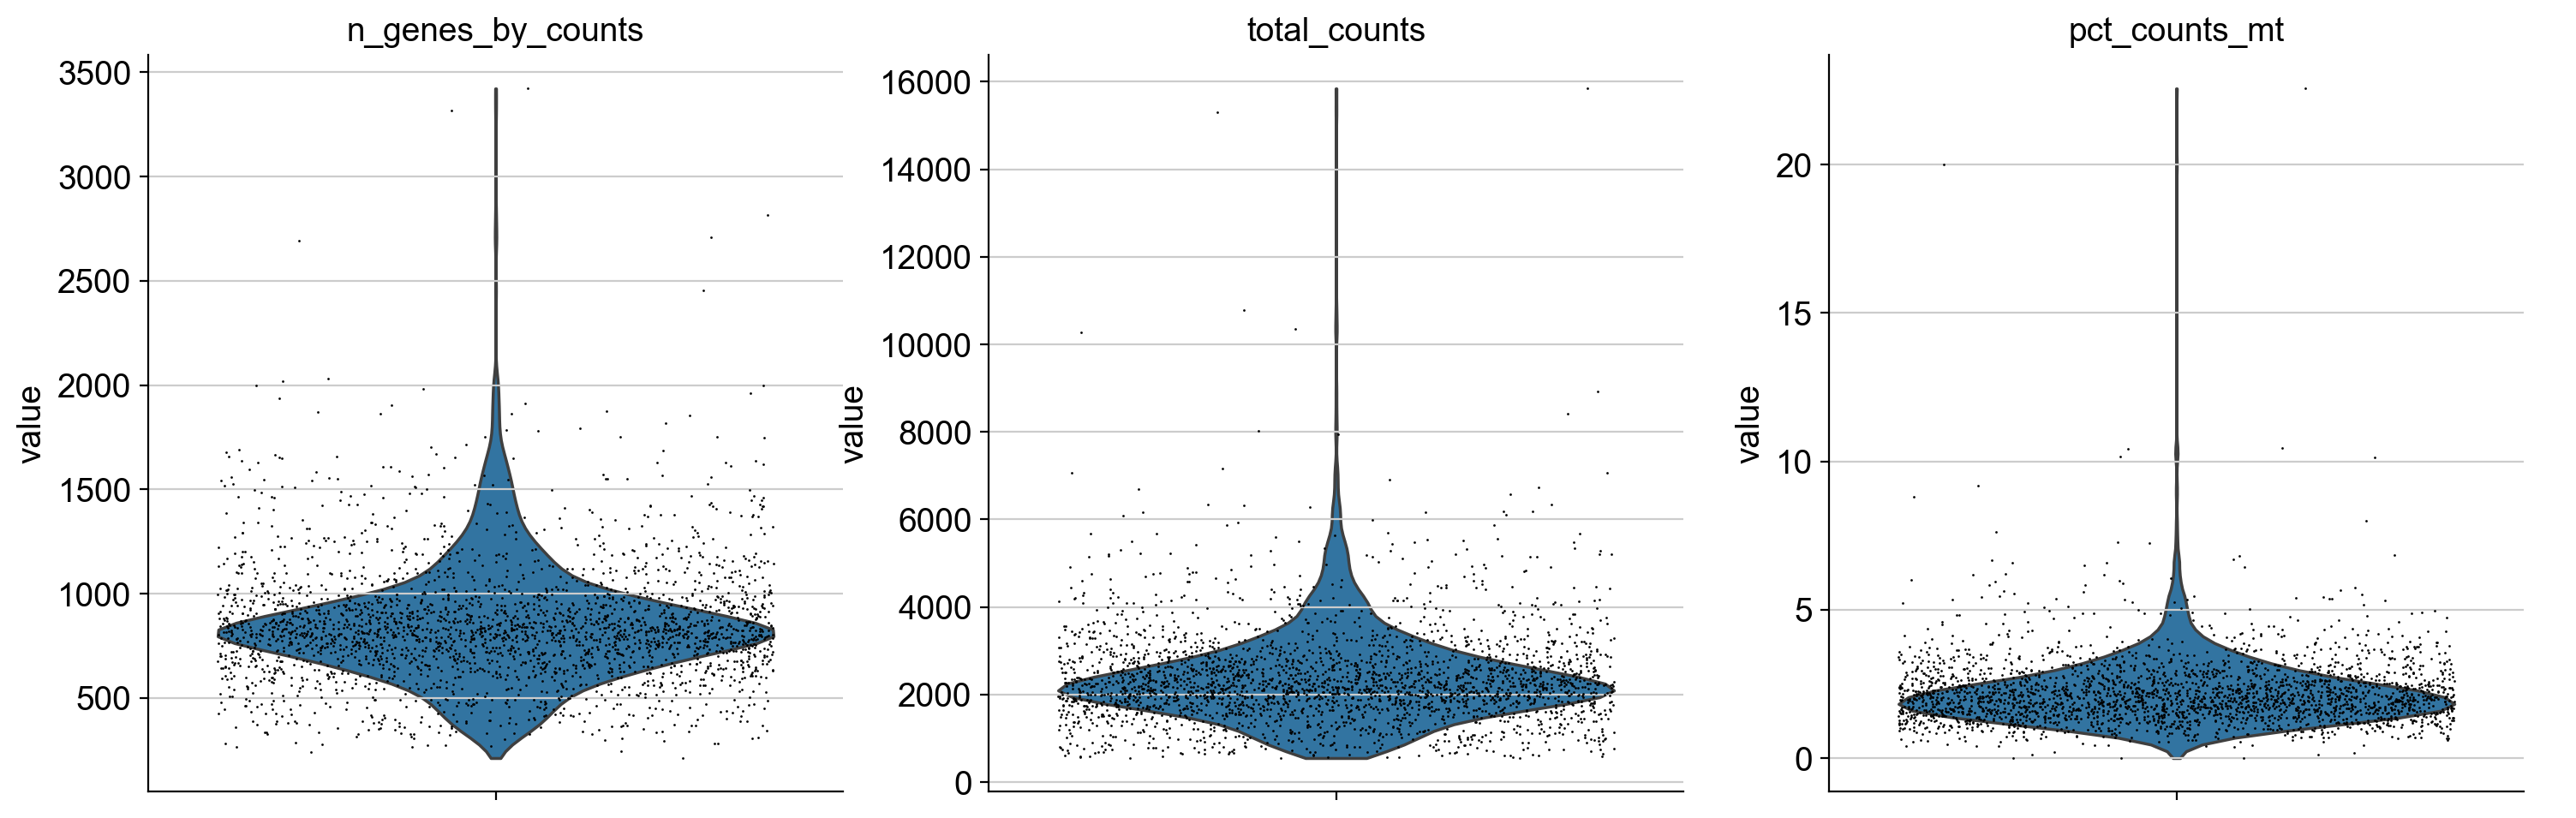

In [4]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
n0 = adata.n_obs

sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True, save="_qc_before.png", show=True)

In [5]:
# Thresholds: look at the violin plots above and justify your own choices.
MIN_GENES, MAX_GENES, MAX_MT = 200, 2500, 5.0

sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[(adata.obs["n_genes_by_counts"] < MAX_GENES) & (adata.obs["pct_counts_mt"] < MAX_MT)].copy()
print(f"cells: {n0} -> {adata.n_obs}   genes: {adata.n_vars}")

filtered out 19024 genes that are detected in less than 3 cells
cells: 2700 -> 2638   genes: 13714


## 3. Doublet detection (Scrublet)
Run on raw counts, before normalization.

In [6]:
sc.pp.scrublet(adata)
print(adata.obs["predicted_doublet"].value_counts())
n_before_doublets = adata.n_obs
adata = adata[~adata.obs["predicted_doublet"]].copy()
print(f"removed {n_before_doublets - adata.n_obs} predicted doublets; {adata.n_obs} cells remain")

Running Scrublet
filtered out 58 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.24
Detected doublet rate = 1.6%
Estimated detectable doublet fraction = 38.3%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 4.3%
    Scrublet finished (0:00:12)
predicted_doublet
False    2595
True       43
Name: count, dtype: int64
removed 43 predicted doublets; 2595 cells remain


## 4. Normalization, feature selection, PCA, UMAP

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
highly variable genes: 1848


d:\Python\Python311\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=50
    finished (0:00:03)


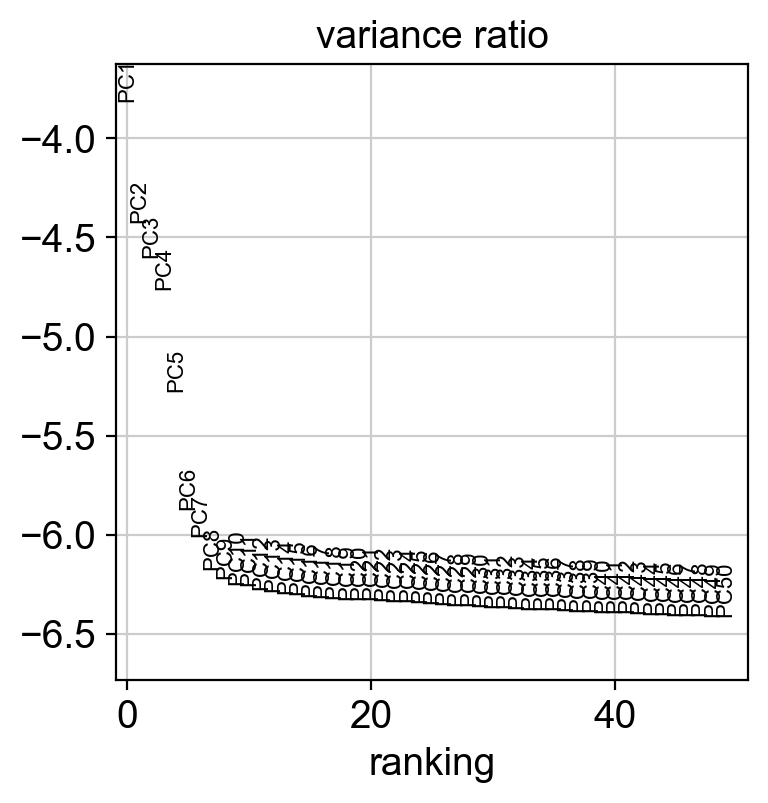

In [7]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata                       # keep full log-normalized matrix for plotting markers

sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
print("highly variable genes:", int(adata.var["highly_variable"].sum()))
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack", random_state=SEED)
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=50, save="_pca_variance.png")

In [8]:
N_PCS = 10                              # pick from the elbow plot above and justify it
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

computing neighbors
    using 'X_pca' with n_pcs = 10


d:\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished (0:00:26)
computing UMAP
    finished (0:00:10)


## 5. Clustering at several resolutions
Higher resolution gives more, smaller clusters. Compare them instead of trusting one default.

running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
{0.2: 6, 0.5: 9, 0.8: 11, 1.2: 15}


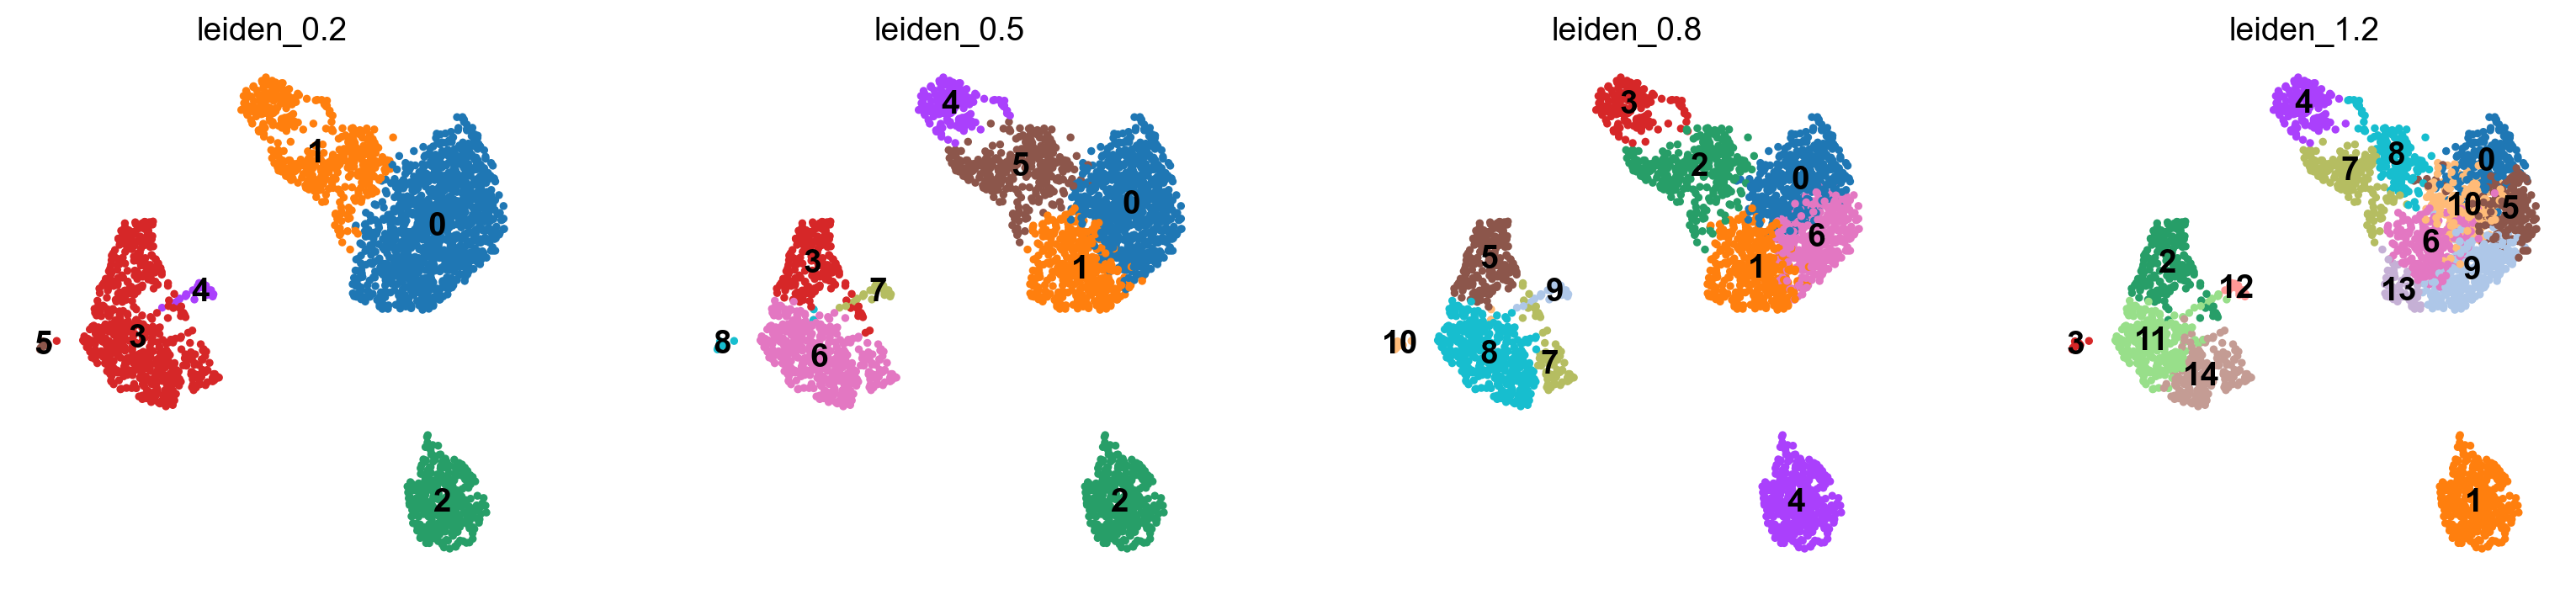

In [9]:
RESOLUTIONS = [0.2, 0.5, 0.8, 1.2]
for r in RESOLUTIONS:
    sc.tl.leiden(adata, resolution=r, key_added=f"leiden_{r}", random_state=SEED,
                 flavor="igraph", n_iterations=2, directed=False)
print({r: adata.obs[f"leiden_{r}"].nunique() for r in RESOLUTIONS})

sc.pl.umap(adata, color=[f"leiden_{r}" for r in RESOLUTIONS], legend_loc="on data",
           save="_resolutions.png")

In [10]:
CHOSEN = 0.5                            # choose after looking at the plots and marker genes
adata.obs["cluster"] = adata.obs[f"leiden_{CHOSEN}"]

## 6. Marker genes and annotation

ranking genes
    finished (0:00:02)


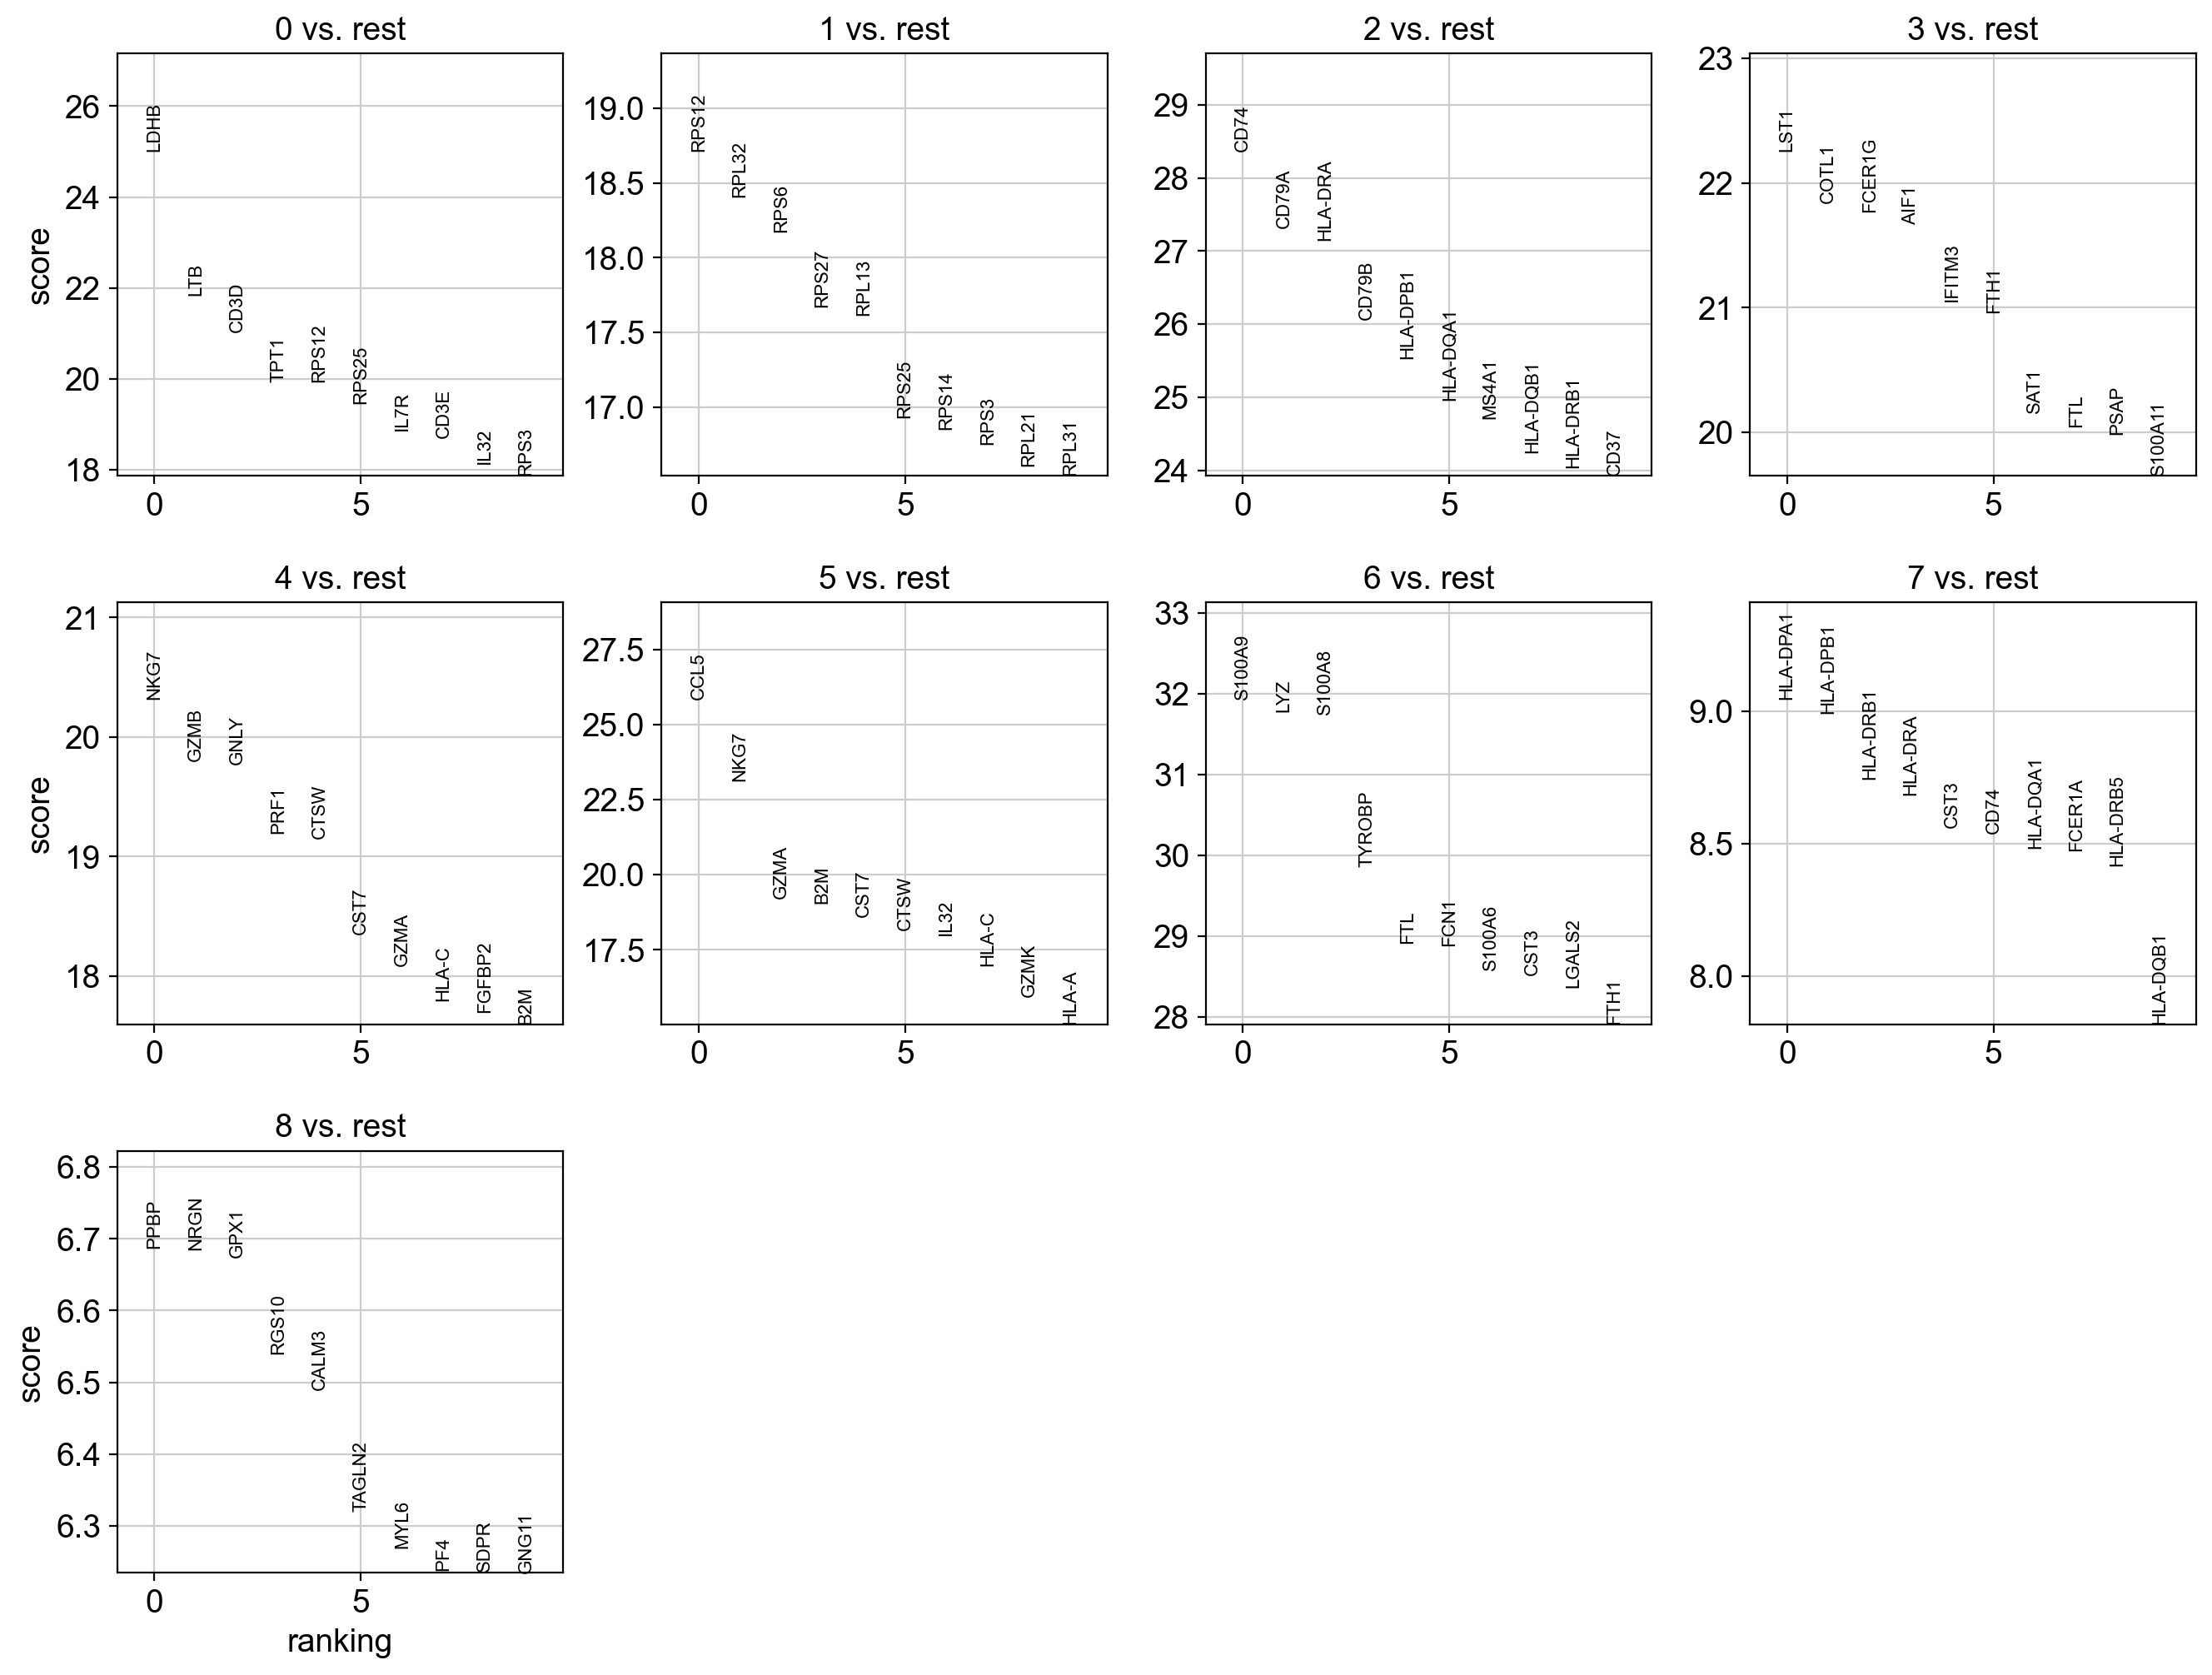

       0      1         2       3      4      5       6         7       8
0   LDHB  RPS12      CD74    LST1   NKG7   CCL5  S100A9  HLA-DPA1    PPBP
1    LTB  RPL32     CD79A   COTL1   GZMB   NKG7     LYZ  HLA-DPB1    NRGN
2   CD3D   RPS6   HLA-DRA  FCER1G   GNLY   GZMA  S100A8  HLA-DRB1    GPX1
3   TPT1  RPS27     CD79B    AIF1   PRF1    B2M  TYROBP   HLA-DRA   RGS10
4  RPS12  RPL13  HLA-DPB1  IFITM3   CTSW   CST7     FTL      CST3   CALM3
5  RPS25  RPS25  HLA-DQA1    FTH1   CST7   CTSW    FCN1      CD74  TAGLN2
6   IL7R  RPS14     MS4A1    SAT1   GZMA   IL32  S100A6  HLA-DQA1    MYL6
7   CD3E   RPS3  HLA-DQB1     FTL  HLA-C  HLA-C    CST3    FCER1A     PF4


In [11]:
sc.tl.rank_genes_groups(adata, "cluster", method="wilcoxon", use_raw=True)
sc.pl.rank_genes_groups(adata, n_genes=10, sharey=False, save="_markers.png")

top = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(8)
print(top)

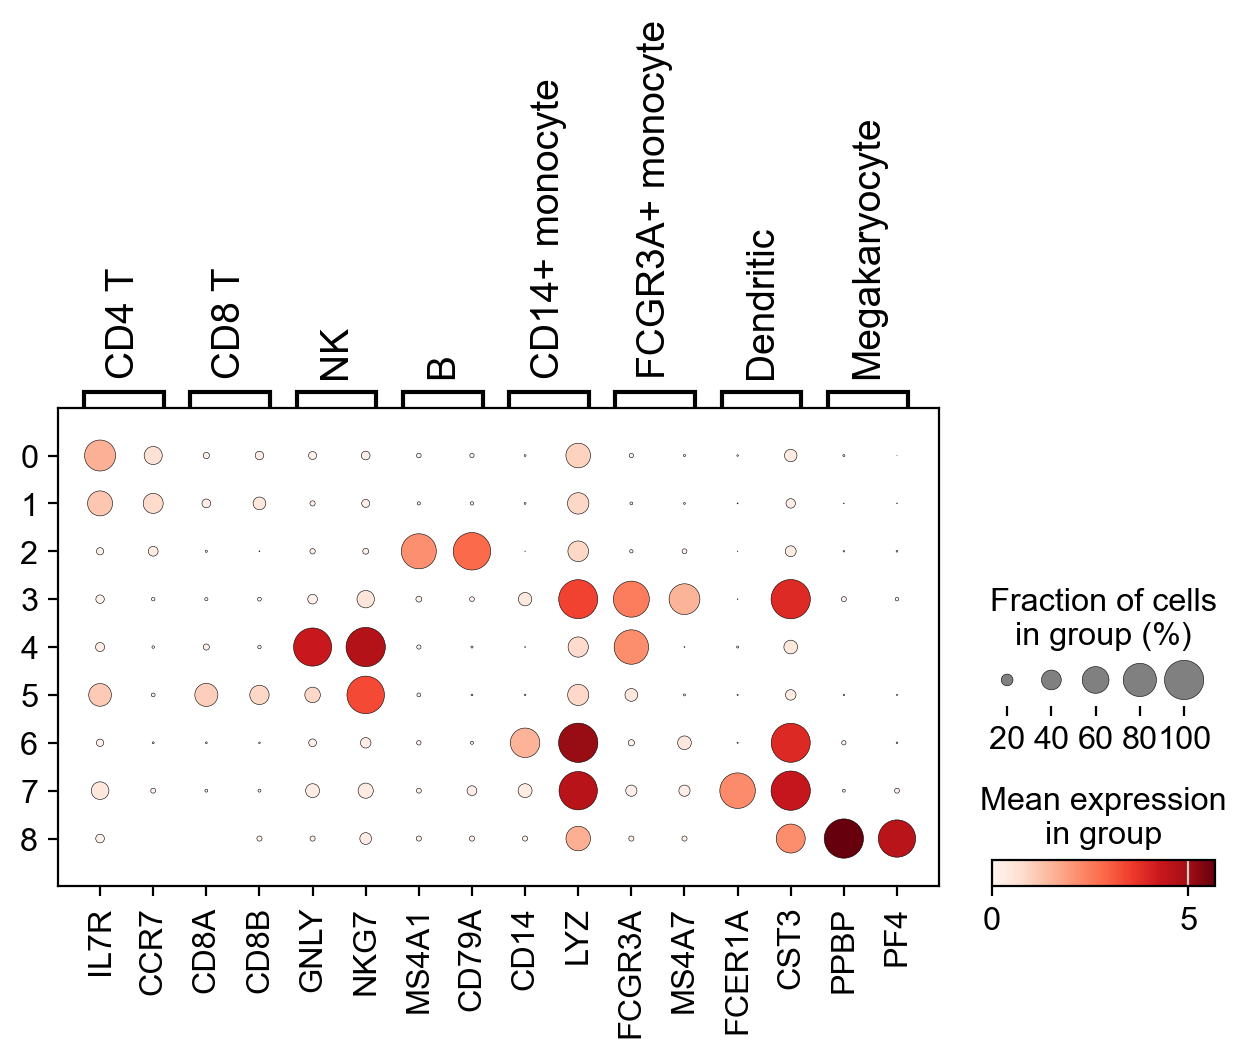

In [12]:
marker_dict = {
    "CD4 T":            ["IL7R", "CCR7"],
    "CD8 T":            ["CD8A", "CD8B"],
    "NK":               ["GNLY", "NKG7"],
    "B":                ["MS4A1", "CD79A"],
    "CD14+ monocyte":   ["CD14", "LYZ"],
    "FCGR3A+ monocyte": ["FCGR3A", "MS4A7"],
    "Dendritic":        ["FCER1A", "CST3"],
    "Megakaryocyte":    ["PPBP", "PF4"],
}
marker_dict = {k: [g for g in v if g in adata.raw.var_names] for k, v in marker_dict.items()}
sc.pl.dotplot(adata, marker_dict, groupby="cluster", use_raw=True, save="_marker_dotplot.png")

In [13]:
# Suggest a label per cluster (mean marker expression), then CONFIRM by eye on the dotplot.
raw_df = pd.DataFrame(adata.raw.X.toarray() if hasattr(adata.raw.X, "toarray") else adata.raw.X,
                      index=adata.obs_names, columns=adata.raw.var_names)
raw_df["cluster"] = adata.obs["cluster"].values
cluster_means = raw_df.groupby("cluster", observed=True).mean()
z = (cluster_means - cluster_means.mean()) / cluster_means.std().replace(0, 1)
suggest = {c: max(marker_dict, key=lambda t: z.loc[c, marker_dict[t]].mean()) for c in z.index}
print(suggest)

{'0': 'CD4 T', '1': 'CD4 T', '2': 'B', '3': 'FCGR3A+ monocyte', '4': 'NK', '5': 'CD8 T', '6': 'CD14+ monocyte', '7': 'Dendritic', '8': 'Megakaryocyte'}


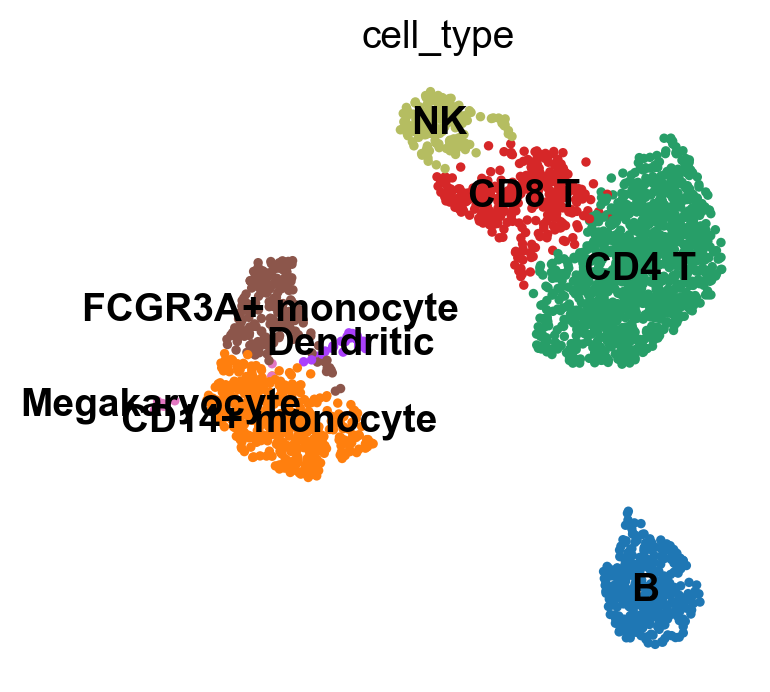

In [14]:
# Edit this mapping after checking the dotplot. Do not accept the suggestion blindly.
cluster_to_type = dict(suggest)
adata.obs["cell_type"] = adata.obs["cluster"].map(cluster_to_type).astype("category")
sc.pl.umap(adata, color="cell_type", legend_loc="on data", save="_cell_types.png")

cell_type
CD4 T               43.6
CD14+ monocyte      16.2
B                   12.6
CD8 T               12.1
FCGR3A+ monocyte     7.7
NK                   6.0
Dendritic            1.2
Megakaryocyte        0.6
Name: proportion, dtype: float64


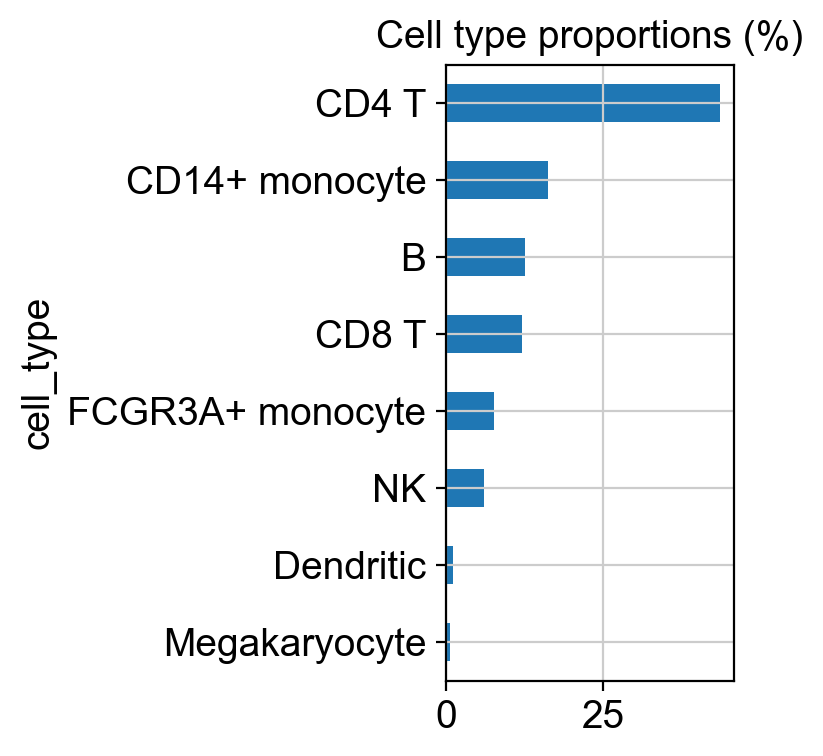

In [15]:
props = adata.obs["cell_type"].value_counts(normalize=True).mul(100).round(1)
print(props)
props.sort_values().plot.barh(title="Cell type proportions (%)")
plt.tight_layout(); plt.savefig("figures/cell_type_proportions.png", dpi=150); plt.show()

## 7. Differential expression between two related groups
Example: the two monocyte populations. Interpret the top genes biologically in your README.

In [16]:
if {"CD14+ monocyte", "FCGR3A+ monocyte"} <= set(adata.obs["cell_type"].unique()):
    sc.tl.rank_genes_groups(adata, "cell_type", groups=["FCGR3A+ monocyte"],
                            reference="CD14+ monocyte", method="wilcoxon", use_raw=True,
                            key_added="de_monocytes")
    de = sc.get.rank_genes_groups_df(adata, group="FCGR3A+ monocyte", key="de_monocytes")
    print(de.head(15))
    de.to_csv("figures/de_monocytes.csv", index=False)
else:
    print("Both monocyte labels not found. Pick two other related groups.")

ranking genes
    finished (0:00:00)
            names     scores  logfoldchanges         pvals     pvals_adj
0          FCGR3A  17.377573        6.126705  1.220090e-67  4.183079e-64
1          IFITM2  16.735552        2.927802  7.218410e-63  1.979865e-59
2           RPS19  15.534693        1.177387  2.020388e-54  4.617934e-51
3            LST1  14.017842        1.281467  1.212459e-44  2.078457e-41
4            RHOC  13.878490        4.014802  8.552617e-44  1.303229e-40
5          FCER1G  13.224280        1.260912  6.354286e-40  7.922061e-37
6           COTL1  13.166675        1.064569  1.364770e-39  1.559705e-36
7             B2M  11.905581        0.627979  1.106900e-32  1.167695e-29
8          IFITM3  11.825029        2.169485  2.898013e-32  2.838810e-29
9            ABI3  11.190419        2.892671  4.542826e-29  3.893770e-26
10           AIF1  11.090746        0.946900  1.391234e-28  1.122316e-25
11          MS4A7  10.712370        2.685476  8.905287e-27  6.427742e-24
12          TI

## 8. Stability check
Re-run neighbors + Leiden with different random seeds and compare to the reference
clustering with the adjusted Rand index (1.0 = identical).

In [17]:
ref = adata.obs["cluster"].values
rows = []
for s in range(1, 6):
    sc.pp.neighbors(adata, n_neighbors=10, n_pcs=N_PCS, random_state=s, key_added=f"nn_{s}")
    sc.tl.leiden(adata, resolution=CHOSEN, random_state=s, neighbors_key=f"nn_{s}",
                 key_added=f"leiden_seed_{s}", flavor="igraph", n_iterations=2, directed=False)
    rows.append({"seed": s,
                 "n_clusters": adata.obs[f"leiden_seed_{s}"].nunique(),
                 "ARI_vs_reference": round(adjusted_rand_score(ref, adata.obs[f"leiden_seed_{s}"]), 3)})
stability = pd.DataFrame(rows)
print(stability)
stability.to_csv("figures/stability.csv", index=False)

computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 10
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
   seed  n_clusters  ARI_vs_reference
0     1           9             0.931
1     2           9             0.763
2     3           9             0.783
3     4           9             0.785
4     5           9             0.787


## 9. Save

In [18]:
# adata.write("pbmc3k_annotated.h5ad")
# print("done")

clusters labelled CD4 T: ['0', '1']
cluster
0    731
1    401
Name: count, dtype: int64
         n_genes_by_counts  total_counts  pct_counts_mt
cluster                                                
0                    868.0        2508.0           1.68
1                    694.0        2019.0           1.92


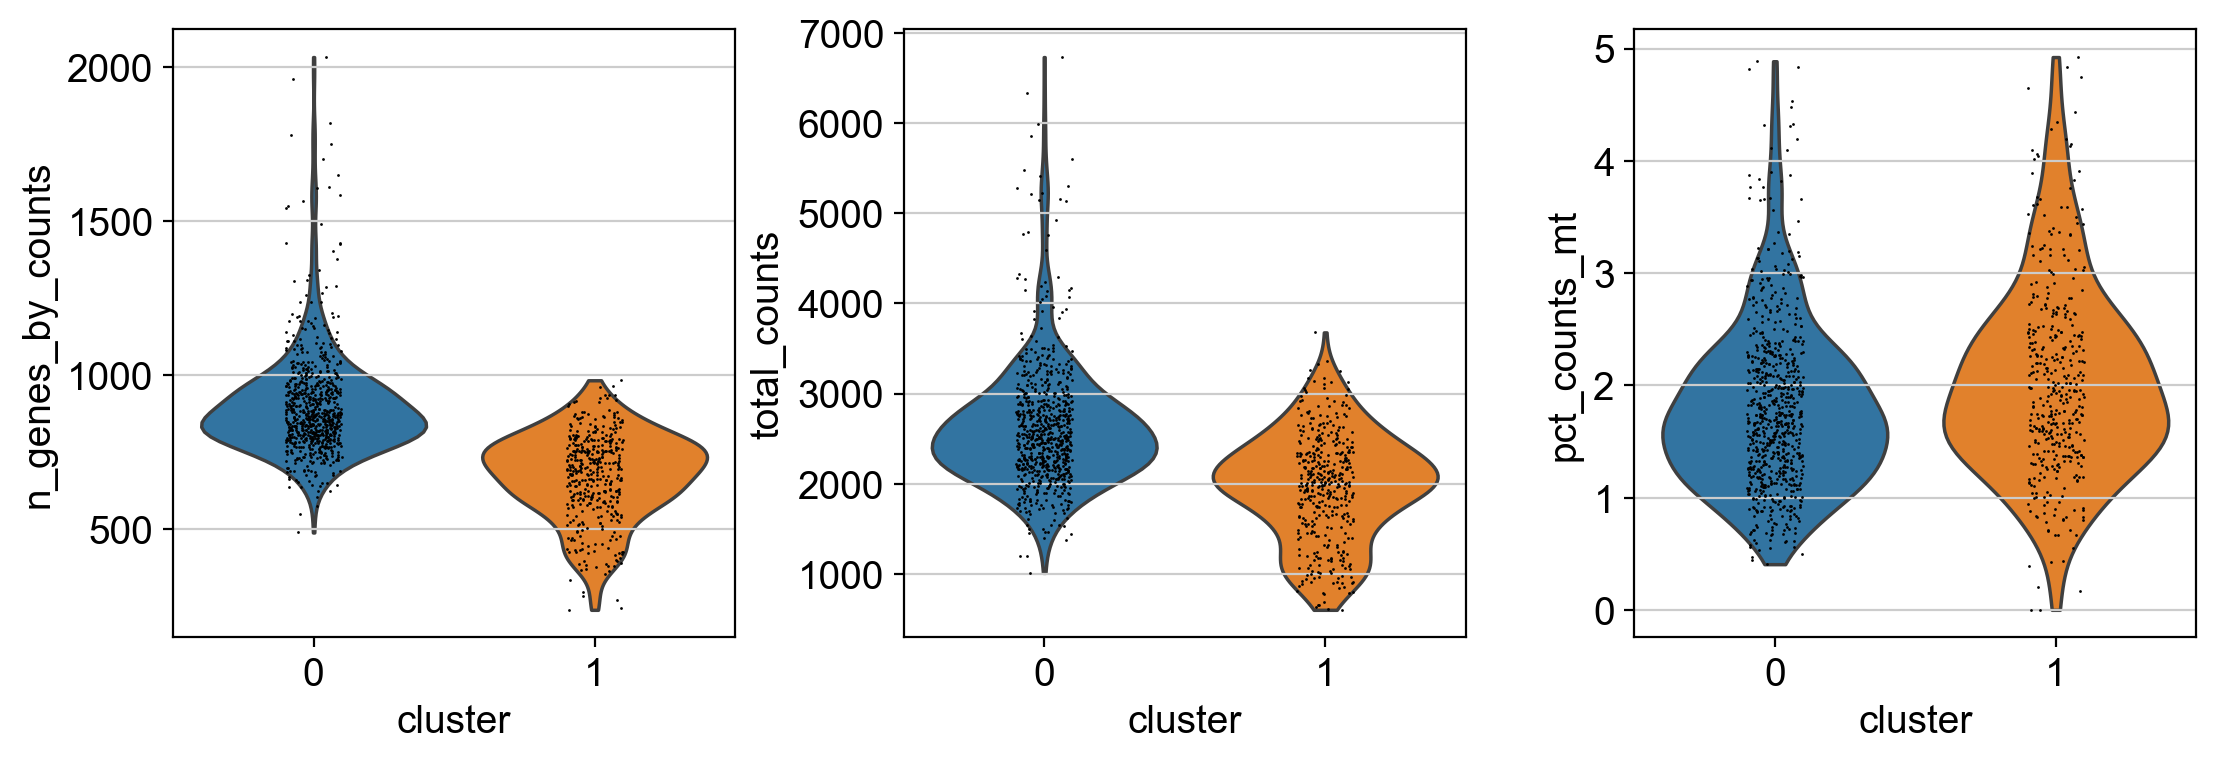

ranking genes
    finished (0:00:00)
Top genes higher in cluster 1:
     names     scores  logfoldchanges         pvals     pvals_adj
0   MALAT1  10.428940        0.409630  1.829170e-25  2.508524e-21
1    RPL32   8.341347        0.231769  7.344941e-17  2.518213e-13
2    RPL13   8.263032        0.238816  1.420183e-16  3.895277e-13
3    RPL21   7.752372        0.229848  9.019162e-15  1.766983e-11
4     RPS6   6.401258        0.186217  1.541025e-10  1.416824e-07
5    RPS23   6.400402        0.188171  1.549683e-10  1.416824e-07
6    RPS27   6.111855        0.158547  9.847960e-10  7.108154e-07
7    RPS3A   6.047702        0.223732  1.469265e-09  1.007475e-06
8    RPS12   5.681411        0.175765  1.335883e-08  6.317346e-06
9    RPS15   5.659646        0.180029  1.516855e-08  6.934051e-06
10   RPL31   5.558522        0.194466  2.720694e-08  1.203600e-05
11    RPL9   5.526493        0.185129  3.266964e-08  1.357671e-05
12   RPL12   5.209148        0.171881  1.897100e-07  5.655832e-05
13    RP

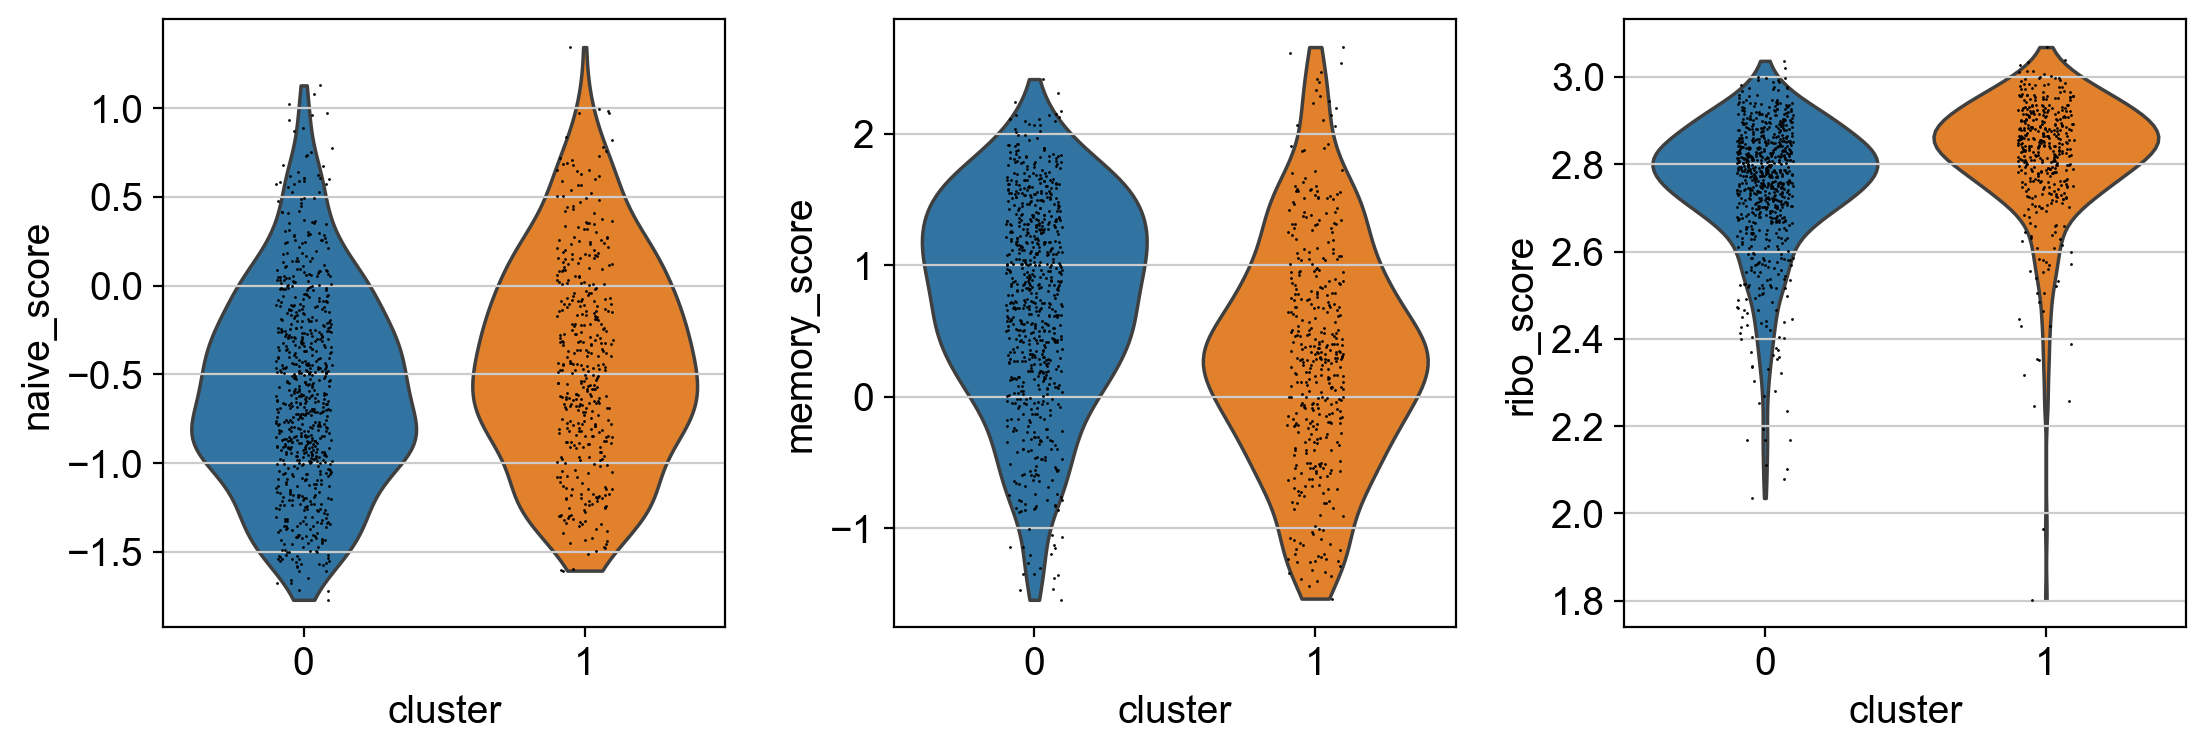

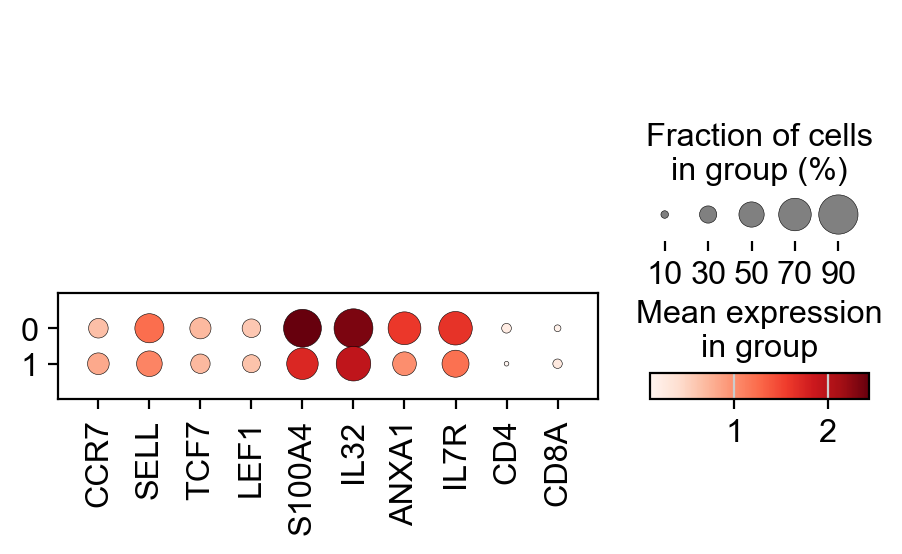

Resolution 0.2 (rows) vs 0.5 (columns):
cluster       0    1    2    3    4    5    6   7   8
leiden_0.2                                           
0           731  397    0    0    0   18    0   0   0
1             0    4    0    0  155  296    0   0   0
2             0    0  326    0    0    0    0   0   0
3             0    0    0  201    0    0  420   1   3
4             0    0    0    0    0    0    0  31   0
5             0    0    0    0    0    0    0   0  12
Seed 1 labels for the CD4 cells (rows = seed-1 cluster, cols = reference cluster):
cluster          0    1
leiden_seed_1          
0              720   35
1               10  366
6                1    0


In [19]:
# %% [markdown]
# ## 10. Look inside the CD4 T cells: what separates the two clusters?
# At resolution 0.5 the CD4 T cells split into two clusters. Question: is this a real
# biological difference (for example naive vs memory T cells) or just a technical effect?
# Paste these cells at the END of the notebook (after the "Save" cell) and run them in order.

# %%
cd4_clusters = [c for c, t in cluster_to_type.items() if t == "CD4 T"]
print("clusters labelled CD4 T:", cd4_clusters)
assert len(cd4_clusters) >= 2, "Need two CD4 T clusters; check cluster_to_type."
A, B = cd4_clusters[0], cd4_clusters[1]          # B is compared against A

cd4 = adata[adata.obs["cluster"].isin([A, B])].copy()
print(cd4.obs["cluster"].value_counts())

# %% [markdown]
# ### 10.1 Technical check: are the two clusters different in quality metrics?
# If one cluster simply has fewer genes/counts, the split may be a quality effect.

# %%
qc_cols = ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
print(cd4.obs.groupby("cluster", observed=True)[qc_cols].median().round(2))

sc.pl.violin(cd4, qc_cols, groupby="cluster", multi_panel=True, save="_cd4_qc.png")

# %% [markdown]
# ### 10.2 Differential expression: cluster B vs cluster A (CD4 T cells only)

# %%
sc.tl.rank_genes_groups(cd4, "cluster", groups=[B], reference=A, method="wilcoxon",
                        use_raw=True, key_added="de_cd4")
de_cd4 = sc.get.rank_genes_groups_df(cd4, group=B, key="de_cd4")
print(f"Top genes higher in cluster {B}:")
print(de_cd4.head(15))
print(f"Top genes higher in cluster {A}:")
print(de_cd4.tail(15).iloc[::-1])
de_cd4.to_csv("figures/de_cd4_clusters.csv", index=False)

# %% [markdown]
# ### 10.3 Biological check: naive vs memory markers
# Naive T cells usually express CCR7, SELL, TCF7, LEF1; memory/activated T cells usually express
# S100A4, IL32, ANXA1. Ribosomal genes (RPS/RPL) are often higher in resting/naive T cells.
# Report what YOU observe; do not assume it matches the textbook.

# %%
def present(genes):
    return [g for g in genes if g in adata.raw.var_names]

naive_genes = present(["CCR7", "SELL", "TCF7", "LEF1"])
memory_genes = present(["S100A4", "IL32", "ANXA1"])
ribo_genes = [g for g in adata.raw.var_names if g.startswith(("RPS", "RPL"))]
print("naive:", naive_genes, "| memory:", memory_genes, "| ribosomal genes:", len(ribo_genes))

score_cols = []
for name, genes in [("naive_score", naive_genes), ("memory_score", memory_genes), ("ribo_score", ribo_genes)]:
    if genes:
        sc.tl.score_genes(cd4, genes, score_name=name, use_raw=True)
        score_cols.append(name)
    else:
        print(f"skipped {name}: none of its genes were found")

scores = cd4.obs.groupby("cluster", observed=True)[score_cols].mean().round(3)
print(scores)
scores.to_csv("figures/cd4_scores.csv")

sc.pl.violin(cd4, score_cols, groupby="cluster", multi_panel=True, save="_cd4_scores.png")
dot_genes = present(naive_genes + memory_genes + ["IL7R", "CD4", "CD8A"])
sc.pl.dotplot(cd4, dot_genes, groupby="cluster", use_raw=True, save="_cd4_dotplot.png")

# %% [markdown]
# ### 10.4 Is the split stable, or an artifact of the resolution?
# Check whether the two clusters merge back at lower resolution and how many CD4 cells
# change cluster when you change the seed.

# %%
tab = pd.crosstab(adata.obs["leiden_0.2"], adata.obs["cluster"])
print("Resolution 0.2 (rows) vs 0.5 (columns):")
print(tab)

if "leiden_seed_1" in adata.obs:
    in_cd4 = adata.obs["cluster"].isin([A, B])
    print("Seed 1 labels for the CD4 cells (rows = seed-1 cluster, cols = reference cluster):")
    print(pd.crosstab(adata.obs.loc[in_cd4, "leiden_seed_1"], adata.obs.loc[in_cd4, "cluster"]))

In [20]:
sub = cd4.obs[(cd4.obs["total_counts"] >= 1500) & (cd4.obs["total_counts"] <= 3000)]
print(sub.groupby("cluster", observed=True)[["memory_score", "naive_score", "ribo_score"]]
      .agg(["median", "count"]).round(2))

        memory_score       naive_score       ribo_score      
              median count      median count     median count
cluster                                                      
0               0.80   573       -0.61   573       2.77   573
1               0.29   298       -0.40   298       2.86   298
